# Phases 3 et 4 : Nettoyage, préparation et feature engineering — Bike Sharing (`hour.csv`)

**Étapes réalisées dans ce notebook :**
1. Charger `hour.csv` et remettre les lignes dans l'ordre chronologique
2. Supprimer `atemp`, `casual`, `registered`, `instant` , `dteday`
3. Fusionner `weathersit = 4` avec `3` (décision de l'EDA : un seul point)
4. Encoder `hr` de façon cyclique (`hr_sin`, `hr_cos`), en gardant aussi `hr` brut pour les arbres
5. Vérifications finales et export du CSV prêt pour l'entraînement : `bike_sharing_final.csv`

> Le fichier final est trié **chronologiquement** : pour le découpage train/test, on coupera par position (jamais de mélange aléatoire).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------- Paramètres -------------------------
DATA_PATH   = "../hour.csv"                  # adapter si besoin (ex. Colab : "/content/hour.csv")
OUTPUT_PATH = "../bike_sharing_final.csv"

COLS_TO_DROP      = ["atemp", "casual", "registered", "instant" , "dteday"]
MERGE_WEATHERSIT  = True    # fusionne weathersit 4 dans 3
KEEP_RAW_HR       = True    # True : garde hr + hr_sin + hr_cos (arbres) ; False : garde seulement sin/cos (modèles linéaires)
# --------------------------------------------------------------

df = pd.read_csv(DATA_PATH, parse_dates=["dteday"])
print("Dimensions initiales :", df.shape)
df.head()

Dimensions initiales : (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


## Phase 3 — Nettoyage et préparation
### 3.1 Ordre chronologique
On trie par `instant` **avant** de le supprimer, puis on vérifie que date + heure sont bien croissantes.

In [3]:
df = df.sort_values("instant").reset_index(drop=True)

ts = df["dteday"] + pd.to_timedelta(df["hr"], unit="h")
assert ts.is_monotonic_increasing and ts.is_unique, "Les lignes ne sont pas chronologiques / timestamps dupliqués"
print("Période :", ts.min(), "->", ts.max())
print("Ordre chronologique vérifié, aucun timestamp dupliqué.")

Période : 2011-01-01 00:00:00 -> 2012-12-31 23:00:00
Ordre chronologique vérifié, aucun timestamp dupliqué.


### 3.2 Suppression des colonnes

| Colonne | Raison |
|---|---|
| `atemp` | Corrélation de 0,99 avec `temp` (redondante) |
| `casual`, `registered` | Fuite de données : `cnt = casual + registered` |
| `instant` | Simple numéro de ligne |

In [4]:
missing = [c for c in COLS_TO_DROP if c not in df.columns]
assert not missing, f"Colonnes introuvables : {missing}"

# Garde-fou : on vérifie la fuite avant de supprimer
print("cnt == casual + registered sur toutes les lignes :", bool((df["cnt"] == df["casual"] + df["registered"]).all()))

df = df.drop(columns=COLS_TO_DROP)
print("Colonnes supprimées :", COLS_TO_DROP)
print("Dimensions :", df.shape)

cnt == casual + registered sur toutes les lignes : True
Colonnes supprimées : ['atemp', 'casual', 'registered', 'instant', 'dteday']
Dimensions : (17379, 12)


### 3.3 Fusion de `weathersit = 4` avec `3`
La catégorie 4 (conditions extrêmes) est quasi inexistante : trop rare pour être apprise.

In [5]:
print("Avant :")
print(df["weathersit"].value_counts().sort_index())

if MERGE_WEATHERSIT:
    df["weathersit"] = df["weathersit"].replace({4: 3})
    print("\nAprès fusion :")
    print(df["weathersit"].value_counts().sort_index())

Avant :
weathersit
1    11413
2     4544
3     1419
4        3
Name: count, dtype: int64

Après fusion :
weathersit
1    11413
2     4544
3     1422
Name: count, dtype: int64


## Phase 4 — Feature engineering
### 4.1 Encodage cyclique de `hr`
Pour un modèle, 23h et 0h sont très éloignées (écart de 23), alors qu'elles sont voisines dans la réalité.
On projette donc l'heure sur un cercle :

- `hr_sin = sin(2π × hr / 24)`
- `hr_cos = cos(2π × hr / 24)`

Les deux colonnes sont nécessaires ensemble : une seule ne distingue pas toutes les heures (par exemple 6h et 18h ont le même `hr_cos`, 3h et 9h ont le même `hr_sin`).

In [6]:
df["hr_sin"] = np.sin(2 * np.pi * df["hr"] / 24)
df["hr_cos"] = np.cos(2 * np.pi * df["hr"] / 24)

if not KEEP_RAW_HR:
    df = df.drop(columns=["hr"])

df[["hr_sin", "hr_cos"]].describe().round(3)

,hr_sin,hr_cos
count,17379.000,17379.000
mean,-0.005,-0.003
std,0.707,0.707
min,-1.000,-1.000
25%,-0.707,-0.707
50%,0.000,-0.000
75%,0.707,0.707
max,1.000,1.000


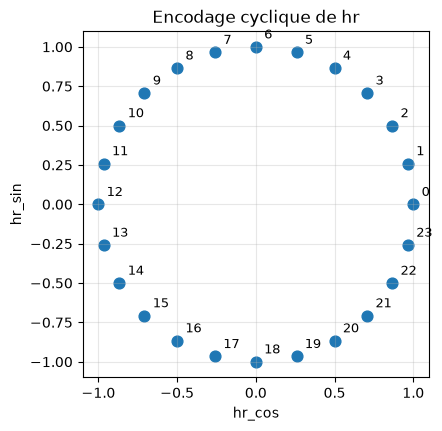

Distance 23h -> 0h  : 0.261   (voisines)
Distance  0h -> 12h : 2.000   (opposées)


In [7]:
# Vérification visuelle : les 24 heures forment un cercle, 23h est voisine de 0h
h = np.arange(24)
x, y = np.cos(2 * np.pi * h / 24), np.sin(2 * np.pi * h / 24)

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(x, y, s=60)
for hh, xx, yy in zip(h, x, y):
    ax.annotate(str(hh), (xx, yy), textcoords="offset points", xytext=(6, 6), fontsize=9)
ax.set(title="Encodage cyclique de hr", xlabel="hr_cos", ylabel="hr_sin")
ax.set_aspect("equal"); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

def dist(a, b):
    return float(np.hypot(x[a] - x[b], y[a] - y[b]))
print(f"Distance 23h -> 0h  : {dist(23, 0):.3f}   (voisines)")
print(f"Distance  0h -> 12h : {dist(0, 12):.3f}   (opposées)")

## Vérifications finales et export

In [9]:
TARGET = "cnt"



# Cible en dernière colonne
features = [c for c in df.columns if c != TARGET]
df = df[features + [TARGET]]

# ---- contrôles qualité ----
assert df.isna().sum().sum() == 0, "Valeurs manquantes détectées"
assert all(pd.api.types.is_numeric_dtype(t) for t in df.dtypes), "Colonne non numérique"
for c in ["casual", "registered", "atemp", "instant"]:
    assert c not in df.columns, f"{c} encore présente"

print("Valeurs manquantes :", int(df.isna().sum().sum()))
print("Lignes identiques (information, non bloquant) :", int(df.duplicated().sum()))
print("Toutes les colonnes sont numériques : OK")
print("Cible :", TARGET, "| Nombre de features :", len(features))
print("\nFeatures :", features)
df.dtypes.to_frame("type").T

Valeurs manquantes : 0
Lignes identiques (information, non bloquant) : 2
Toutes les colonnes sont numériques : OK
Cible : cnt | Nombre de features : 13

Features : ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'hum', 'windspeed', 'hr_sin', 'hr_cos']


,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,hum,windspeed,hr_sin,hr_cos,cnt
type,int64,int64,int64,int64,int64,int64,int64,int64,float64,float64,float64,float64,float64,int64


In [10]:
df.to_csv(OUTPUT_PATH, index=False)
print(f"Fichier enregistré : {OUTPUT_PATH}   -> {df.shape[0]:,} lignes × {df.shape[1]} colonnes")

# relecture de contrôle
check = pd.read_csv(OUTPUT_PATH)
assert check.shape == df.shape and list(check.columns) == list(df.columns)
check.head(10)

Fichier enregistré : ../bike_sharing_final.csv   -> 17,379 lignes × 14 colonnes


,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,hum,windspeed,hr_sin,hr_cos,cnt
0,1,0,1,0,0,6,0,1,0.24,0.81,0.0000,0.000000,1.000000e+00,16
1,1,0,1,1,0,6,0,1,0.22,0.80,0.0000,0.258819,9.659258e-01,40
2,1,0,1,2,0,6,0,1,0.22,0.80,0.0000,0.500000,8.660254e-01,32
3,1,0,1,3,0,6,0,1,0.24,0.75,0.0000,0.707107,7.071068e-01,13
4,1,0,1,4,0,6,0,1,0.24,0.75,0.0000,0.866025,5.000000e-01,1
5,1,0,1,5,0,6,0,2,0.24,0.75,0.0896,0.965926,2.588190e-01,1
6,1,0,1,6,0,6,0,1,0.22,0.80,0.0000,1.000000,6.123234e-17,2
7,1,0,1,7,0,6,0,1,0.20,0.86,0.0000,0.965926,-2.588190e-01,3
8,1,0,1,8,0,6,0,1,0.24,0.75,0.0000,0.866025,-5.000000e-01,8
9,1,0,1,9,0,6,0,1,0.32,0.76,0.0000,0.707107,-7.071068e-01,14


## Récapitulatif

| Étape | Résultat |
|---|---|
| Colonnes supprimées | `atemp`, `casual`, `registered`, `instant` (+ `dteday` après le tri) |
| Nettoyage | `weathersit = 4` fusionné avec `3` |
| Nouvelles variables | `hr_sin`, `hr_cos` (`hr` brut conservé) |
| Fichier final | `bike_sharing_final.csv`, trié chronologiquement, 100 % numérique, sans valeur manquante, cible `cnt` en dernière colonne |

**Utilisation selon le modèle :**
- **Arbres / boosting** (Random Forest, XGBoost, LightGBM) : utiliser `hr` + `hr_sin` + `hr_cos` (valeur par défaut).
- **Modèles linéaires** (Ridge, Lasso) : mettre `KEEP_RAW_HR = False`, et plus tard encoder `season`, `weathersit` en one-hot.

**Prochaines étapes (Phase 4, suite) :** variable d'interaction `workingday × hr` ou `day_type`, éventuellement encodage cyclique de `mnth` et `weekday`, lags et moyennes glissantes.